<a href="https://colab.research.google.com/github/SrustiUB/Data-Science/blob/main/EMWA_VaR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

EWMA VaR BACKTEST
            Model  Violations  Violation Rate (%)
0  Historical VaR         109                5.11
1        EWMA VaR         106                4.97

Better Model : EWMA VaR


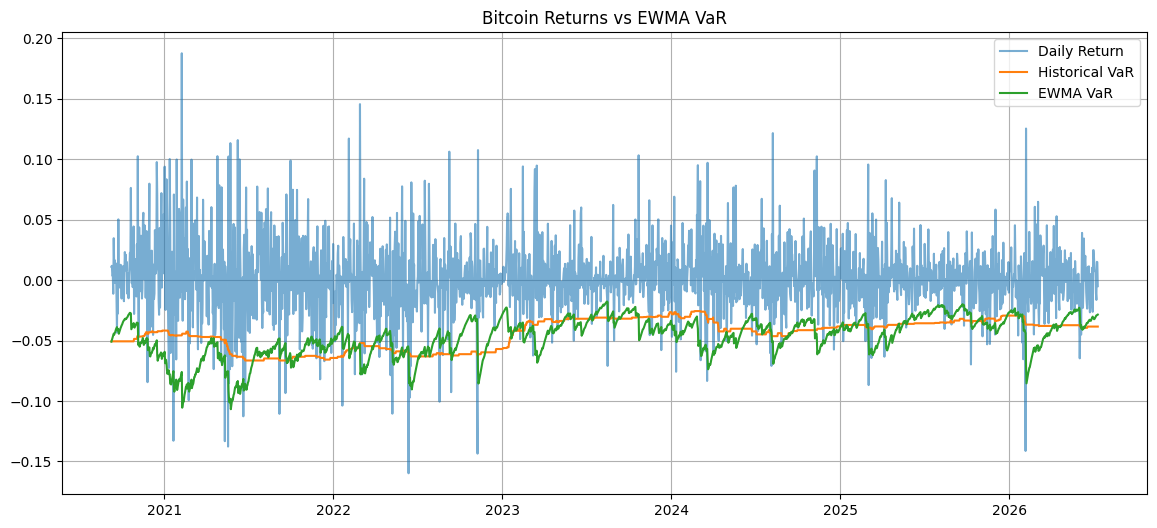

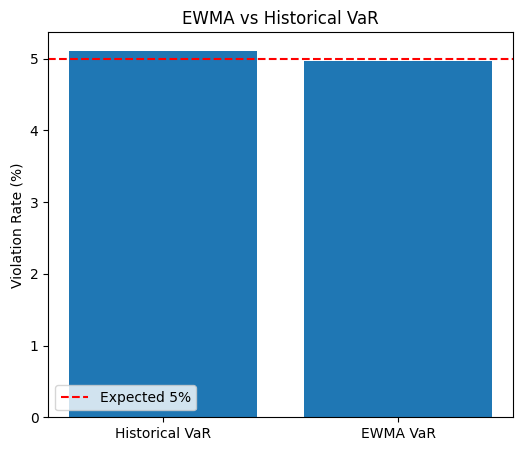


Results saved as EWMA_vs_Historical_VaR.csv


In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ==========================================================
# EWMA VaR vs Historical VaR
# ==========================================================

# Download Bitcoin Data
df = yf.download(
    "BTC-USD",
    start="2020-01-01",
    auto_adjust=True,
    progress=False
)

# Fix MultiIndex
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

df = df[["Close"]].copy()

# Daily Returns
df["Return"] = df["Close"].pct_change()

returns = df["Return"].dropna()

# ==========================================================
# Parameters
# ==========================================================

window = 252
confidence = 0.95
alpha = 1 - confidence

# RiskMetrics decay factor
lam = 0.94

z = -1.645   # 95% VaR

# ==========================================================
# Historical VaR
# ==========================================================

historical_var = (
    returns
    .rolling(window)
    .quantile(alpha)
)

# ==========================================================
# EWMA Volatility
# ==========================================================

ewma_var = np.zeros(len(returns))

# Initialize variance
ewma_var[0] = returns.var()

for i in range(1, len(returns)):
    ewma_var[i] = (
        lam * ewma_var[i-1]
        + (1-lam) * returns.iloc[i-1]**2
    )

ewma_vol = np.sqrt(ewma_var)

# EWMA VaR
ewma_var95 = -z * ewma_vol

# Convert to negative loss threshold
ewma_var95 = -ewma_var95

# ==========================================================
# Results
# ==========================================================

result = pd.DataFrame({

    "Return":returns,

    "Historical_VaR":historical_var,

    "EWMA_VaR":ewma_var95

}).dropna()

# ==========================================================
# Backtesting
# ==========================================================

result["Hist_Violation"] = (
    result["Return"] <
    result["Historical_VaR"]
)

result["EWMA_Violation"] = (
    result["Return"] <
    result["EWMA_VaR"]
)

# ==========================================================
# Statistics
# ==========================================================

hist_rate = result["Hist_Violation"].mean()*100
ewma_rate = result["EWMA_Violation"].mean()*100

summary = pd.DataFrame({

    "Model":[
        "Historical VaR",
        "EWMA VaR"
    ],

    "Violations":[
        result["Hist_Violation"].sum(),
        result["EWMA_Violation"].sum()
    ],

    "Violation Rate (%)":[
        hist_rate,
        ewma_rate
    ]

})

print("="*50)
print("EWMA VaR BACKTEST")
print("="*50)

print(summary.round(2))

expected = 5

if abs(hist_rate-expected) < abs(ewma_rate-expected):
    print("\nBetter Model : Historical VaR")
else:
    print("\nBetter Model : EWMA VaR")

# ==========================================================
# Plot
# ==========================================================

plt.figure(figsize=(14,6))

plt.plot(
    result.index,
    result["Return"],
    label="Daily Return",
    alpha=0.6
)

plt.plot(
    result.index,
    result["Historical_VaR"],
    label="Historical VaR"
)

plt.plot(
    result.index,
    result["EWMA_VaR"],
    label="EWMA VaR"
)

plt.legend()

plt.grid(True)

plt.title("Bitcoin Returns vs EWMA VaR")

plt.show()

# ==========================================================
# Violation Comparison
# ==========================================================

plt.figure(figsize=(6,5))

plt.bar(
    summary["Model"],
    summary["Violation Rate (%)"]
)

plt.axhline(
    5,
    color="red",
    linestyle="--",
    label="Expected 5%"
)

plt.ylabel("Violation Rate (%)")

plt.title("EWMA vs Historical VaR")

plt.legend()

plt.show()

# ==========================================================
# Save
# ==========================================================

summary.to_csv(
    "EWMA_vs_Historical_VaR.csv",
    index=False
)

print("\nResults saved as EWMA_vs_Historical_VaR.csv")